In [ ]:
!pip install lightning-flash[tabular] 2>&1 | tail -n 15


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 114.2 MB/s  0:00:00
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel: finished with status 'error'
ERROR: Failed to build 'numpy' when getting requirements to build wheel


In [2]:
!pip install lightning -q
from google.colab import files
uploaded = files.upload()   # utils.py, dataset_base.csv, dataset_with_technicals.csv

Saving utils.py to utils.py


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import lightning as L
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from utils import load_split, evaluate

paths = {"base": "dataset_base.csv", "tech": "dataset_with_technicals.csv"}
print(torch.__version__, L.__version__)

2.11.0+cpu 2.6.6


In [4]:
class MLPRegressor(L.LightningModule):
    def __init__(self, n_features, hidden=(32, 16), dropout=0.3, lr=1e-3, wd=1e-2):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nn.Linear(n_features, hidden[0]), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden[0], hidden[1]), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden[1], 1),
        )
        self.loss = nn.MSELoss()

    def forward(self, x):
        return self.net(x).squeeze(-1)

    def training_step(self, batch, _):
        x, y = batch
        loss = self.loss(self(x), y)
        self.log("train_loss", loss, on_epoch=True, prog_bar=False)
        return loss

    def validation_step(self, batch, _):
        x, y = batch
        self.log("val_loss", self.loss(self(x), y), prog_bar=False)

    def configure_optimizers(self):
        return torch.optim.AdamW(self.parameters(), lr=self.hparams.lr,
                                 weight_decay=self.hparams.wd)


def loader(X, y, shuffle):
    ds = TensorDataset(torch.tensor(X, dtype=torch.float32),
                       torch.tensor(y, dtype=torch.float32))
    # shuffling rows within the training set is fine; the split itself stays chronological
    return DataLoader(ds, batch_size=32, shuffle=shuffle)


def run_lightning(path, seeds=range(3)):
    X_tr, X_te, y_tr, y_te = load_split(path)
    n_val = int(len(X_tr) * 0.15)
    X_sub, X_val = X_tr.iloc[:-n_val], X_tr.iloc[-n_val:]
    y_sub, y_val = y_tr.iloc[:-n_val], y_tr.iloc[-n_val:]

    sc = StandardScaler().fit(X_sub)
    y_mu, y_sd = y_sub.mean(), y_sub.std()
    Xs, Xv, Xt = sc.transform(X_sub), sc.transform(X_val), sc.transform(X_te)
    ys = ((y_sub - y_mu) / y_sd).values
    yv = ((y_val - y_mu) / y_sd).values

    preds = []
    for s in seeds:
        L.seed_everything(s, workers=True)
        model = MLPRegressor(Xs.shape[1])
        ckpt = ModelCheckpoint(monitor="val_loss", mode="min", save_top_k=1)
        trainer = L.Trainer(
            max_epochs=200, accelerator="auto", logger=False,
            enable_progress_bar=False, enable_model_summary=False,
            callbacks=[EarlyStopping(monitor="val_loss", patience=20), ckpt],
        )
        trainer.fit(model, loader(Xs, ys, True), loader(Xv, yv, False))
        best = MLPRegressor.load_from_checkpoint(ckpt.best_model_path)
        best.eval()
        with torch.no_grad():
            p = best(torch.tensor(Xt, dtype=torch.float32)).numpy()
        preds.append(p * y_sd + y_mu)
        print(f"  seed {s}: stopped after {trainer.current_epoch + 1} epochs, "
              f"best val loss = {ckpt.best_model_score:.3f}", flush=True)

    return np.mean(preds, axis=0), y_te, y_tr.mean()


results, store = [], {}
for k, p in paths.items():
    print(f"--- {k} ---", flush=True)
    pred, y_te, mu = run_lightning(p)
    store[k] = dict(pred=pred, y_te=y_te)
    results.append({**evaluate(y_te, pred, mu, "PyTorch Lightning MLP"), "data": k})

res = pd.DataFrame(results).set_index(["data", "model"])
print(res.round(4))
res.to_csv("lightning_results.csv")

--- base ---


INFO: Seed set to 0
INFO:lightning.fabric.utilities.seed:Seed set to 0
INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and t

  seed 0: stopped after 35 epochs, best val loss = 1.612


INFO: Seed set to 1
INFO:lightning.fabric.utilities.seed:Seed set to 1
INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/callbacks/model_checkpoint.py:881: Checkpoint directory /content/checkpoints exists and is not empty.


  seed 1: stopped after 32 epochs, best val loss = 1.587


...

  seed 0: stopped after 29 epochs, best val loss = 1.590


INFO: Seed set to 1
INFO:lightning.fabric.utilities.seed:Seed set to 1
INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


  seed 1: stopped after 37 epochs, best val loss = 1.585


INFO: Seed set to 2
INFO:lightning.fabric.utilities.seed:Seed set to 2
INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


  seed 2: stopped after 28 epochs, best val loss = 1.594
                              RMSE     MAE      R2  R2_OOS  DirAcc
data model                                                        
base PyTorch Lightning MLP  0.0363  0.0260  0.0217  0.0229  0.4743
tech PyTorch Lightning MLP  0.0370  0.0265 -0.0092 -0.0083  0.4855


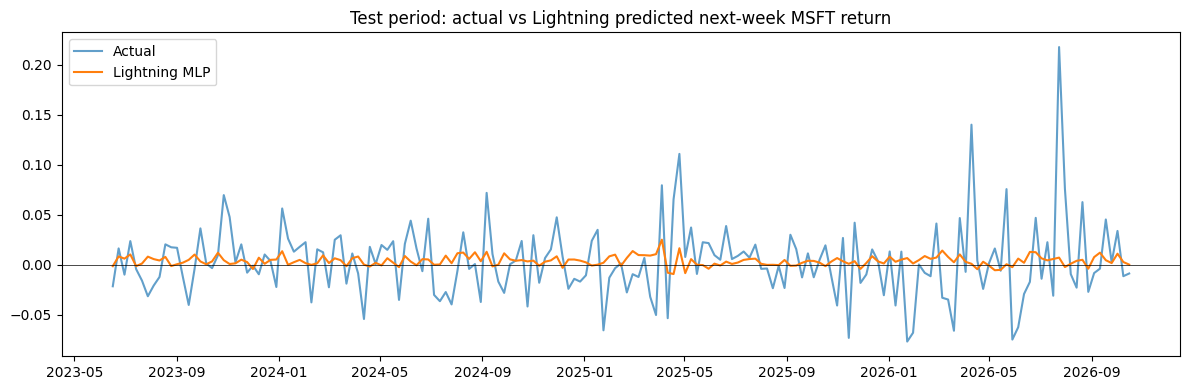

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
k = "base"
plt.figure(figsize=(12, 4))
plt.plot(store[k]["y_te"].index, store[k]["y_te"].values, label="Actual", alpha=0.7)
plt.plot(store[k]["y_te"].index, store[k]["pred"], label="Lightning MLP")
plt.axhline(0, color="k", lw=0.5)
plt.title("Test period: actual vs Lightning predicted next-week MSFT return")
plt.legend(); plt.tight_layout()
plt.savefig("18_lightning_pred_vs_actual.png", dpi=150)
plt.show()

from google.colab import files
for f in ["lightning_results.csv", "18_lightning_pred_vs_actual.png"]:
    files.download(f)